
# 05 - Model Evaluation

## Objective

The objective of this notebook is to evaluate the final Random Forest model using the unseen test dataset.

The model was trained and saved in the previous notebook. In this notebook, we will load the saved model and evaluate its predictive performance without retraining it.

## Evaluation Scope

- Load the saved model and decision threshold.
- Recreate the original train-test split.
- Generate predictions on the test dataset.
- Evaluate classification performance.
- Analyze the confusion matrix.
- Visualize ROC and Precision-Recall curves.
- Interpret the model's strengths and limitations.

## Final Model Configuration

- Model: Random Forest Classifier
- Number of estimators: 200
- Class weight: Balanced
- Decision threshold: 0.45
- Test size: 20%
- Random state: 42


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve,
    average_precision_score
)

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")


Libraries imported successfully.



## 1. Load Dataset

Load the original dataset to recreate the same test split used during model development.


In [ ]:
file_path=Path.cwd().parent / "data" / "raw" / "Telco_customer_churn.xlsx"

df = pd.read_excel(
    file_path,
    sheet_name = "Telco_Churn"
)
df.head()


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.5,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.3,Yes,1,89,5340,Competitor had better devices


In [4]:

X = df.drop(columns=[
    "CustomerID",
    "Churn Label",
    "Churn Value",
    "Churn Reason",
    "Churn Score",
    "CLTV",
    "Count",
    "Country",
    "State"
])

y = df["Churn Value"]

X["Total Charges"] = pd.to_numeric(
    X["Total Charges"].astype(str).str.strip(),
    errors="coerce"
)

print("X shape:", X.shape)
print("y shape:", y.shape)


X shape: (7043, 24)
y shape: (7043,)


In [5]:

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training set:", X_train.shape)
print("Testing set:", X_test.shape)

print("\nTest target distribution:")
print(y_test.value_counts(normalize=True))


Training set: (5634, 24)
Testing set: (1409, 24)

Test target distribution:
Churn Value
0    0.734564
1    0.265436
Name: proportion, dtype: float64



## 2. Load Final Model

Load the trained Random Forest pipeline and its selected decision threshold.


In [6]:

model_path = Path("../models/final_random_forest.pkl")

saved_artifact = joblib.load(model_path)

final_rf_model = saved_artifact["model"]
final_threshold = saved_artifact["threshold"]

print("Model loaded successfully.")
print("Decision threshold:", final_threshold)


Model loaded successfully.
Decision threshold: 0.45



## 3. Generate Predictions

Generate churn probability scores for the test dataset and convert them into binary predictions using the selected decision threshold.


In [7]:

y_test_proba = final_rf_model.predict_proba(X_test)[:, 1]

y_test_pred = (
    y_test_proba >= final_threshold
).astype(int)

print("Probability predictions:", y_test_proba[:10])
print("Class predictions:", y_test_pred[:10])


Probability predictions: [0.035 0.755 0.095 0.51  0.04  0.76  0.51  0.175 0.005 0.59 ]
Class predictions: [0 1 0 1 0 1 1 0 0 1]


In [8]:

evaluation_results = {
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Precision": precision_score(y_test, y_test_pred),
    "Recall": recall_score(y_test, y_test_pred),
    "F1-Score": f1_score(y_test, y_test_pred),
    "ROC-AUC": roc_auc_score(y_test, y_test_proba),
    "Average Precision": average_precision_score(y_test, y_test_proba)
}

evaluation_df = pd.DataFrame(
    evaluation_results.items(),
    columns=["Metric", "Score"]
)

evaluation_df["Score"] = evaluation_df["Score"].round(4)

evaluation_df


,Metric,Score
0,Accuracy,0.7729
1,Precision,0.5551
2,Recall,0.7273
3,F1-Score,0.6296
4,ROC-AUC,0.8438
5,Average Precision,0.6435



## 4. Confusion Matrix

Analyze the number of correct and incorrect predictions made by the final model.


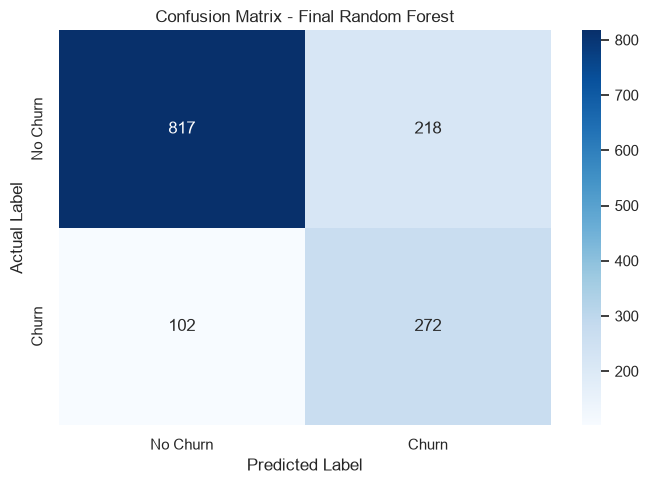

In [9]:

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Churn", "Churn"],
    yticklabels=["No Churn", "Churn"]
)

plt.title("Confusion Matrix - Final Random Forest")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


In [10]:

print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=["No Churn", "Churn"],
        digits=4
    )
)


              precision    recall  f1-score   support

    No Churn     0.8890    0.7894    0.8362      1035
       Churn     0.5551    0.7273    0.6296       374

    accuracy                         0.7729      1409
   macro avg     0.7221    0.7583    0.7329      1409
weighted avg     0.8004    0.7729    0.7814      1409




## 5. ROC Curve

The ROC curve evaluates the model's ability to distinguish between churn and non-churn customers across different classification thresholds.

The Area Under the Curve (ROC-AUC) summarizes the model's ranking performance.


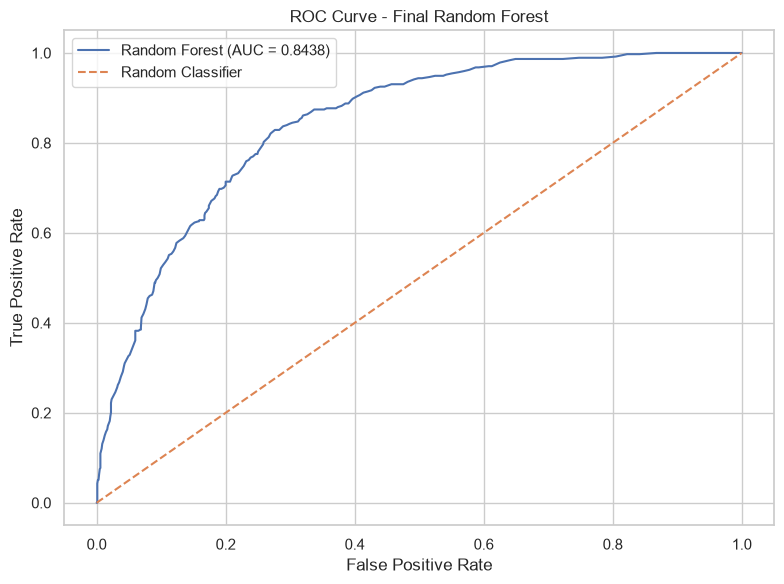

In [11]:

fpr, tpr, roc_thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(8, 6))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest (AUC = {roc_auc_score(y_test, y_test_proba):.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Final Random Forest")
plt.legend()
plt.tight_layout()
plt.show()



## 6. Precision-Recall Curve

The Precision-Recall curve illustrates the trade-off between precision and recall across different classification thresholds.

It is particularly useful for evaluating performance when the target classes are imbalanced.


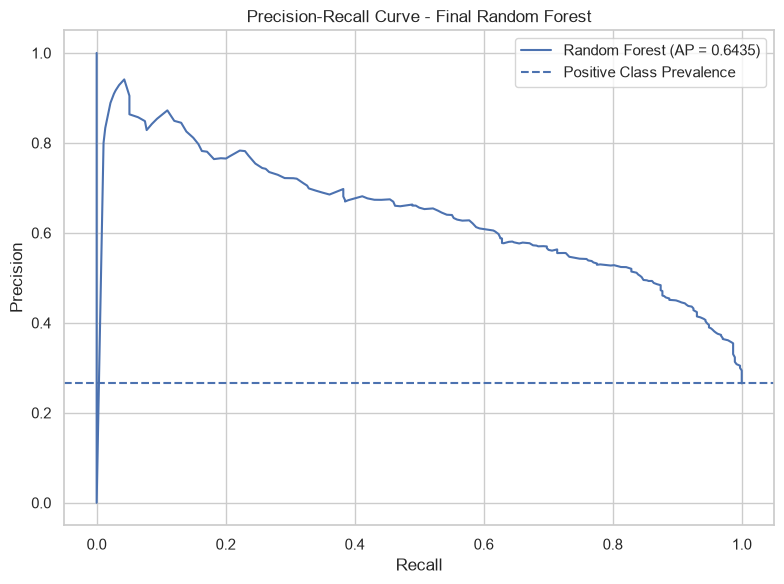

In [12]:

precision_values, recall_values, pr_thresholds = precision_recall_curve(
    y_test,
    y_test_proba
)

average_precision = average_precision_score(
    y_test,
    y_test_proba
)

plt.figure(figsize=(8, 6))

plt.plot(
    recall_values,
    precision_values,
    label=f"Random Forest (AP = {average_precision:.4f})"
)

plt.axhline(
    y=y_test.mean(),
    linestyle="--",
    label="Positive Class Prevalence"
)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-Recall Curve - Final Random Forest")
plt.legend()
plt.tight_layout()
plt.show()



## 7. Threshold Analysis

Analyze how different decision thresholds affect precision, recall, and F1-score on the test dataset.

The threshold was selected using the validation dataset in the previous notebook. Test results are used only for final evaluation and not for further threshold optimization.


In [13]:

thresholds = np.arange(0.30, 0.65, 0.05)

threshold_results = []

for threshold in thresholds:
    predictions = (y_test_proba >= threshold).astype(int)

    threshold_results.append({
        "Threshold": threshold,
        "Precision": precision_score(y_test, predictions),
        "Recall": recall_score(y_test, predictions),
        "F1-Score": f1_score(y_test, predictions)
    })

threshold_df = pd.DataFrame(threshold_results)

threshold_df.round(4)


,Threshold,Precision,Recall,F1-Score
0,0.30,0.4837,0.8743,0.6229
1,0.35,0.5114,0.8369,0.6349
2,0.40,0.5299,0.7807,0.6314
3,0.45,0.5551,0.7273,0.6296
4,0.50,0.5702,0.6845,0.6221
5,0.55,0.5770,0.6310,0.6028
6,0.60,0.6128,0.5882,0.6003


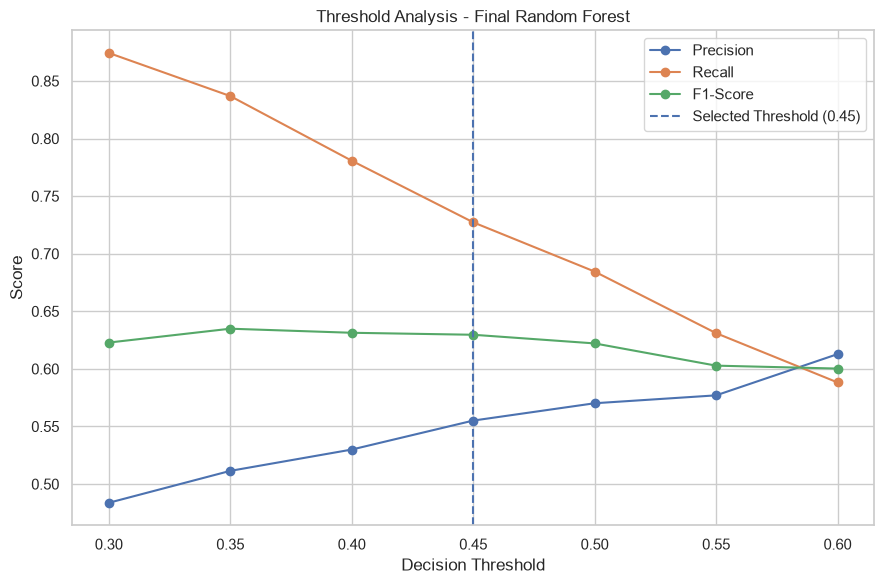

In [14]:

plt.figure(figsize=(9, 6))

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Precision"],
    marker="o",
    label="Precision"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["Recall"],
    marker="o",
    label="Recall"
)

plt.plot(
    threshold_df["Threshold"],
    threshold_df["F1-Score"],
    marker="o",
    label="F1-Score"
)

plt.axvline(
    x=final_threshold,
    linestyle="--",
    label=f"Selected Threshold ({final_threshold})"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Score")
plt.title("Threshold Analysis - Final Random Forest")
plt.legend()
plt.tight_layout()
plt.show()



## 8. Final Evaluation Summary

### Model Performance

The final Random Forest model achieved the following results on the unseen test dataset:

| Metric | Score |
|---|---:|
| Accuracy | 0.7729 |
| Precision | 0.5551 |
| Recall | 0.7273 |
| F1-Score | 0.6296 |
| ROC-AUC | 0.8438 |
| Average Precision | 0.6435 |

### Confusion Matrix Analysis

- True Negatives: 817
- False Positives: 218
- False Negatives: 102
- True Positives: 272

The model correctly identified 272 churn customers out of 374 actual churn customers.

It missed 102 churn customers and incorrectly flagged 218 non-churn customers.

### Strengths

- The model identifies approximately 72.73% of actual churn customers.
- ROC-AUC of 0.8438 indicates good ranking ability.
- The selected threshold provides a balance between precision and recall.
- The model performs better at identifying non-churn customers than churn customers.

### Limitations

- Churn precision is 55.51%, meaning a considerable number of churn predictions are false positives.
- The model misses approximately 27.27% of actual churn customers.
- The model's performance depends on the selected decision threshold.
- The model has not yet been evaluated for probability calibration or performance on future customer data.

### Conclusion

The final Random Forest model demonstrates promising performance for customer churn prediction.

The model achieves a recall of 72.73% and an ROC-AUC of 0.8438, indicating that it can identify a substantial proportion of churn customers and distinguish between churn and non-churn customers.

However, the precision of 55.51% indicates that further improvements may be needed to reduce false positive predictions.

The model should be considered a decision-support tool rather than a definitive predictor of customer behavior.



## Key Takeaways

- Evaluated the saved Random Forest model on the original unseen test dataset.
- Achieved an ROC-AUC of 0.8438 and an F1-score of 0.6296.
- Identified 72.73% of actual churn customers using a 0.45 decision threshold.
- Analyzed classification errors using a confusion matrix.
- Evaluated model performance through ROC and Precision-Recall curves.
- Investigated the impact of different decision thresholds without modifying the selected threshold.
